<a href="https://colab.research.google.com/github/CharlieHubbard7/Datathon2026/blob/main/DSC_Datathon_2026_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CMU Data Science Club Datathon 2026

---


**Team Name:** The Humanitarians

**Names:** Charlie Hubbard, Ada Kablawi, Eddie Liu

**Andrew IDs:** Cjhubbar, Akablawi, Eddieliu

**This notebook is only for reference to help your team download the data and get started. Using this notebook is not required.**

##Preprocessing!

In [118]:
### Load Some Common Packages ###
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

In [119]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


We provide datasets from the United Nations. You may use any number of the datasets, and we encourage you to find your own datasets either entirely or supplementarily. Refer to the dataset schemas - the column description tables in the instructions packet - to understand what information is contained in the datasets. Additionally, we have provided some guiding questions but feel free to go beyond those.

In [120]:
!pip install gdown

In [121]:
!gdown 15cX26m-Gz_5urG3juTU9A-fRdgO5x_mX -O ../data/project_targeting/
!gdown 1P1BRPe-SqRnJohCF6L4SabPx4iI8BJ86 -O ../data/geo_mismatch/
!unzip ../data/project_targeting/project_targeting_data.zip -d ../data/project_targeting/
!unzip ../data/geo_mismatch/geo_mismatch_data.zip -d ../data/geo_mismatch/

Downloading...
From: https://drive.google.com/uc?id=15cX26m-Gz_5urG3juTU9A-fRdgO5x_mX
To: /data/project_targeting/project_targeting_data.zip
100% 2.38M/2.38M [00:00<00:00, 14.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1P1BRPe-SqRnJohCF6L4SabPx4iI8BJ86
To: /data/geo_mismatch/geo_mismatch_data.zip
100% 16.9M/16.9M [00:00<00:00, 59.0MB/s]
Archive:  ../data/project_targeting/project_targeting_data.zip
replace ../data/project_targeting/Data_ CERF Donor Contributions and Allocations - allocations.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: ../data/project_targeting/Data_ CERF Donor Contributions and Allocations - allocations.csv  
replace ../data/project_targeting/CERF Climate Related Allocations - CERF climate related allocations.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: Archive:  ../data/geo_mismatch/geo_mismatch_data.zip
replace ../data/geo_mismatch/humanitarian-response-plans.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [122]:
#loading all the data
df_hrp = pd.read_csv("/content/drive/MyDrive/ipynb stuff/humanitarian-response-plans.csv")
df_cod_a0 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin0.csv")
df_cod_a1 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin1.csv")
df_cod_a2 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin2.csv")
df_cod_a3 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin3.csv")
df_cod_a4 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin4.csv")
df_cod_a4 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin4.csv")
df_hpc_2024 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/hpc_hno_2024.csv")
df_hpc_2025 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/hpc_hno_2025.csv")

df_finances = pd.read_csv("/content/drive/MyDrive/ipynb stuff/Data_ Country Based Pooled Funds (CBPF) - Projects.csv")


/tmp/ipython-input-16399920.py:4: DtypeWarning: Columns (4,5,6,7,8,9,13,14,15,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cod_a1 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin1.csv")
/tmp/ipython-input-16399920.py:5: DtypeWarning: Columns (6,7,8,9,13,14,15,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cod_a2 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin2.csv")
/tmp/ipython-input-16399920.py:6: DtypeWarning: Columns (8,9,13,14,15,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cod_a3 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/cod_population_admin3.csv")
/tmp/ipython-input-16399920.py:9: DtypeWarning: Columns (1,2,3,4,5,6,10,11,12,13,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df_hpc_2024 = pd.read_csv("/content/drive/MyDrive/ipynb stuff/hpc_hno_2024.csv")
/tmp/ipython-input-16399920.p

##Financial Dataset

In [142]:
# Clean country names
df_finances["PooledFundName"] = (df_finances["PooledFundName"].replace({"oPt": "Occupied Palestinian Territory"}).str.replace(r"\s*\(RhPF\)", "", regex=True))
df_finances = df_finances[df_finances["PooledFundName"] != "Occupied Palestinian Territory"]
# Group and count projects
cbpf_counts = (df_finances.groupby("PooledFundName").size().reset_index(name="Project_Count").sort_values("Project_Count", ascending=False))

cbpf_counts

,PooledFundName,Project_Count
0,Afghanistan,118
19,Ukraine,91
16,Sudan,89
12,Nigeria,76
14,Somalia,75
15,South Sudan,68
7,Lebanon,68
5,Ethiopia,67
10,Myanmar,59
17,Syria,54


In [143]:
country_to_iso3 = {
    "Afghanistan": "AFG",
    "Somalia": "SOM",
    "South Sudan": "SSD",
    "Sudan": "SDN",
    "Syria": "SYR",
    "Syria Cross border": "SYR",
    "Yemen": "YEM",
    "DRC": "COD",
    "Occupied Palestinian Territory": "PSE",
    "CAR": "CAF",
    "Nigeria": "NGA",
    "Iraq": "IRQ",
    "Lebanon": "LBN",
    "Myanmar": "MMR",
    "Ukraine": "UKR",
    "Pakistan": "PAK",
    "Jordan": "JOR",
    "Venezuela": "VEN",
    "Burkina Faso": "BFA",
    "Niger": "NER",
    "Colombia": "COL",
    "Haiti": "HTI",
    "Mali": "MLI",
    "Chad": "TCD",
    "Mozambique": "MOZ",
    "Ethiopia": "ETH"
}

df_finances["Country ISO3"] = df_finances["PooledFundName"].map(country_to_iso3)
#df_finances[df_finances["Country ISO3"].isna()]
df_finances[df_finances["Country ISO3"].isna()][["PooledFundName"]].drop_duplicates()


,PooledFundName


In [144]:
print(df_finances.columns)
df_finances = df_finances[df_finances["AllocationYear"] == 2025]
#df_finances[["Budget", "TotalSupportCost", "TotalDirectCost", "ProjectSummary"]]
df_finances.head()

Index(['PooledFundName', 'PooledFundId', 'AllocationTypeId', 'ChfId',
       'ChfProjectCode', 'ExternalProjectCode', 'AllocationType',
       'AllocationYear', 'AllocationSourceID', 'AllocationSourceName',
       'OrganizationName', 'OrganizationType', 'ProjectTitle',
       'ProjectStartDate', 'ProjectEndDate', 'ProjectDuration', 'Budget',
       'TotalDirectCost', 'TotalSupportCost', 'DateSubmitted', 'Men', 'Women',
       'Boys', 'Girls', 'ProjectSummary', 'IndirectBeneficiaries',
       'CatchmentPopulation', 'AllocationStrategy', 'HumanitarianContext',
       'GrantRequestJustification', 'DescriptionOfBeneficiaries',
       'NeedsAssessment', 'Activities', 'ImplementationPlan',
       'Monitoring_Eval', 'CrossCuttingIssues', 'EnvironmentMarker',
       'GenderMarker', 'GenderTheme', 'FieldSecurity', 'Access',
       'ActualStartDate', 'ActualEndDate', 'ProjectStatus', 'ProjectStatusId',
       'ProjectStatusCode', 'ProcessStatus', 'ProcessStatusId', 'PartnerCode',
       'Allocat

,PooledFundName,PooledFundId,AllocationTypeId,ChfId,ChfProjectCode,ExternalProjectCode,AllocationType,AllocationYear,AllocationSourceID,AllocationSourceName,...,ActualEndDate,ProjectStatus,ProjectStatusId,ProjectStatusCode,ProcessStatus,ProcessStatusId,PartnerCode,AllocationTypeCategoryId,AllocationTypeCategory,Country ISO3
1232,Afghanistan,23,62,35077,CBPF-AFG-25-R-UN-35077,NaN,2025 1st Reserve Allocation,2025,1,Reserve,...,2026-05-17,Implementation & Reporting,119,PRJ_IMPL_RPT,Implementation,6,50179.9878,0,NaN,AFG
1233,Afghanistan,23,62,35078,CBPF-AFG-25-R-UN-35078,NaN,2025 1st Reserve Allocation,2025,1,Reserve,...,2026-06-14,Implementation & Reporting,119,PRJ_IMPL_RPT,Implementation,6,54907.0881,0,NaN,AFG
1234,Afghanistan,23,62,35079,CBPF-AFG-25-R-INGO-35079,NaN,2025 1st Reserve Allocation,2025,1,Reserve,...,2026-05-17,Implementation & Reporting,119,PRJ_IMPL_RPT,Implementation,6,167993.8722,1,Core activities,AFG
1235,Afghanistan,23,62,35080,CBPF-AFG-25-R-INGO-35080,NaN,2025 1st Reserve Allocation,2025,1,Reserve,...,2026-05-10,Implementation & Reporting,119,PRJ_IMPL_RPT,Implementation,6,40725.7872,0,NaN,AFG
1236,Afghanistan,23,62,35082,CBPF-AFG-25-R-INGO-35082,NaN,2025 1st Reserve Allocation,2025,1,Reserve,...,2026-04-22,Implementation & Reporting,119,PRJ_IMPL_RPT,Implementation,6,128358.9543,1,Core activities,AFG


##HPC Dataset

In [126]:
df_hpc_2025.head()

,Country ISO3,Admin 1 PCode,Admin 1 Name,Admin 2 PCode,Admin 2 Name,Admin 3 PCode,Admin 3 Name,Description,Cluster,Category,Population,In Need,Targeted,Affected,Reached,Info
0,#country+code,#adm1+code,#adm1+name,#adm2+code,#adm2+name,#adm3+code,#adm3+name,#sector+description,#sector+cluster+code,#category,#population,#inneed,#targeted,#affected,#reached,#meta+info
1,AFG,NaN,NaN,NaN,NaN,NaN,NaN,Final HRP caseload,ALL,NaN,46024352,22887726,16790412,NaN,18100000,NaN
2,AFG,NaN,NaN,NaN,NaN,NaN,NaN,Final HRP caseload,ALL,Adults,20999996,10241973,7737415,NaN,NaN,NaN
3,AFG,NaN,NaN,NaN,NaN,NaN,NaN,Final HRP caseload,ALL,Boys,12241703,5927993,4431106,NaN,NaN,NaN
4,AFG,NaN,NaN,NaN,NaN,NaN,NaN,Final HRP caseload,ALL,Children,24035916,12188191,8707494,NaN,NaN,NaN


In [127]:
df_hpc_2025_cleaned = df_hpc_2025[df_hpc_2025["Reached"].notna()].copy()
print(len(df_hpc_2025_cleaned))
df_hpc_2025_cleaned = df_hpc_2025_cleaned.reset_index(drop=True)
df_hpc_2025_cleaned = df_hpc_2025_cleaned.dropna(axis=1, how="any")
df_hpc_2025_cleaned = df_hpc_2025_cleaned.iloc[1:]
df_hpc_2025_cleaned['In Need'] = pd.to_numeric(df_hpc_2025_cleaned['In Need'], errors='coerce')
df_hpc_2025_cleaned['Population'] = pd.to_numeric(df_hpc_2025_cleaned['Population'], errors='coerce')
df_hpc_2025_cleaned['Reached'] = pd.to_numeric(df_hpc_2025_cleaned['Reached'], errors='coerce')
df_hpc_2025_cleaned['Targeted'] = pd.to_numeric(df_hpc_2025_cleaned['Targeted'], errors='coerce')

# Creating new Columns
df_hpc_2025_cleaned['Need Intensity'] = df_hpc_2025_cleaned['In Need'] / (df_hpc_2025_cleaned['Population'])
df_hpc_2025_cleaned['Response Coverage'] = df_hpc_2025_cleaned['Reached'] / (df_hpc_2025_cleaned['In Need'])
df_hpc_2025_cleaned['Targeting Efficiency'] = df_hpc_2025_cleaned['Reached'] / (df_hpc_2025_cleaned['Targeted'])
df_hpc_2025_cleaned['Unmet Need'] = df_hpc_2025_cleaned['In Need'] - (df_hpc_2025_cleaned['Reached'])
df_hpc_2025_cleaned['Neglect Severity'] = (df_hpc_2025_cleaned['In Need'] - (df_hpc_2025_cleaned['Reached'])) / (df_hpc_2025_cleaned['Population'])

#Next Part
# df_hpc_2025_cleaned["Need Intensity Score"] = (df_hpc_2025_cleaned["Need Intensity"].rank(pct=True) * 100)

#Unmet_Need = In_Need - Reached
# df_hpc_2025_cleaned.head(23)

# 1) flip coverage so LOW coverage = HIGH priority
df_hpc_2025_cleaned["Low Coverage"] = 1 - df_hpc_2025_cleaned["Response Coverage"]

# 2) percentile scores (0–100) so everything is comparable
df_hpc_2025_cleaned["Need Intensity Score"] = df_hpc_2025_cleaned["Need Intensity"].rank(pct=True) * 100
df_hpc_2025_cleaned["Neglect Severity Score"] = df_hpc_2025_cleaned["Neglect Severity"].rank(pct=True) * 100
df_hpc_2025_cleaned["Unmet Need Score"] = df_hpc_2025_cleaned["Unmet Need"].rank(pct=True) * 100
df_hpc_2025_cleaned["Low Coverage Score"] = df_hpc_2025_cleaned["Low Coverage"].rank(pct=True) * 100

# 3) weighted composite (tweak weights if you want)
df_hpc_2025_cleaned["UN Priority Score"] = (
    0.35 * df_hpc_2025_cleaned["Neglect Severity Score"] +
    0.30 * df_hpc_2025_cleaned["Need Intensity Score"] +
    0.20 * df_hpc_2025_cleaned["Unmet Need Score"] +
    0.15 * df_hpc_2025_cleaned["Low Coverage Score"]
).round(1)

min_score = df_hpc_2025_cleaned["UN Priority Score"].min()
max_score = df_hpc_2025_cleaned["UN Priority Score"].max()

df_hpc_2025_cleaned["UN Priority Score (35–100)"] = (
    35
    + (df_hpc_2025_cleaned["UN Priority Score"] - min_score)
    / (max_score - min_score)
    * (100 - 35)
).round(1)

# 4) quick view: highest priority first
df_hpc_2025_cleaned.sort_values("UN Priority Score", ascending=False).head(23)




23


,Country ISO3,Description,Cluster,Population,In Need,Targeted,Reached,Need Intensity,Response Coverage,Targeting Efficiency,Unmet Need,Neglect Severity,Low Coverage,Need Intensity Score,Neglect Severity Score,Unmet Need Score,Low Coverage Score,UN Priority Score,UN Priority Score (35–100)
22,YEM,Final HRP Caseload,ALL,34879018.0,19540217.0,10527030.0,5300000.0,0.560228,0.271235,0.503466,14240217.0,0.408275,0.728765,90.909091,100.000000,100.000000,68.181818,92.5,100.0
18,SSD,2025 South Sudan Plan,ALL,13442554.0,9290088.0,5386982.0,3900000.0,0.691095,0.419802,0.723968,5390088.0,0.400972,0.580198,100.000000,95.454545,68.181818,31.818182,81.8,91.8
15,SDN,Final caseload,ALL,46790687.0,30440770.0,20934770.0,20900000.0,0.650573,0.686579,0.998339,9540770.0,0.203903,0.313421,95.454545,68.181818,90.909091,13.636364,72.7,84.9
19,TCD,Final HRP caseload,ALL,19373666.0,7049226.0,5475571.0,2000000.0,0.363856,0.283719,0.365259,5049226.0,0.260623,0.716281,72.727273,81.818182,63.636364,59.090909,72.0,84.4
9,HTI,Final figures,ALL,11899555.0,5986456.0,3941924.0,2200000.0,0.503082,0.367496,0.558103,3786456.0,0.318201,0.632504,86.363636,86.363636,45.454545,40.909091,71.4,83.9
20,UKR,Plan HNRP Caseload,ALL,35765386.0,12708866.0,6016366.0,4800000.0,0.355340,0.377689,0.797824,7908866.0,0.221132,0.622311,68.181818,77.272727,81.818182,36.363636,69.3,82.3
21,VEN,Final HRP caseload,ALL,27112332.0,7943720.0,5125664.0,2000000.0,0.292993,0.251771,0.390193,5943720.0,0.219226,0.748229,59.090909,72.727273,72.727273,72.727273,68.6,81.8
3,CAF,CAR HNRP 2025,ALL,5296124.0,2440338.0,1772631.0,720000.0,0.460778,0.295041,0.406176,1720338.0,0.324830,0.704959,77.272727,90.909091,22.727273,54.545455,67.7,81.1
6,COL,Final caseload,ALL,53110609.0,9053352.0,1991880.0,890000.0,0.170462,0.098306,0.446814,8163352.0,0.153705,0.901694,40.909091,50.000000,86.363636,90.909091,60.7,75.7
10,MLI,Final HNRP Caseload,ALL,23134540.0,6431534.0,4709012.0,1800000.0,0.278006,0.279871,0.382246,4631534.0,0.200200,0.720129,54.545455,63.636364,54.545455,63.636364,59.1,74.5


##Plotting HPC

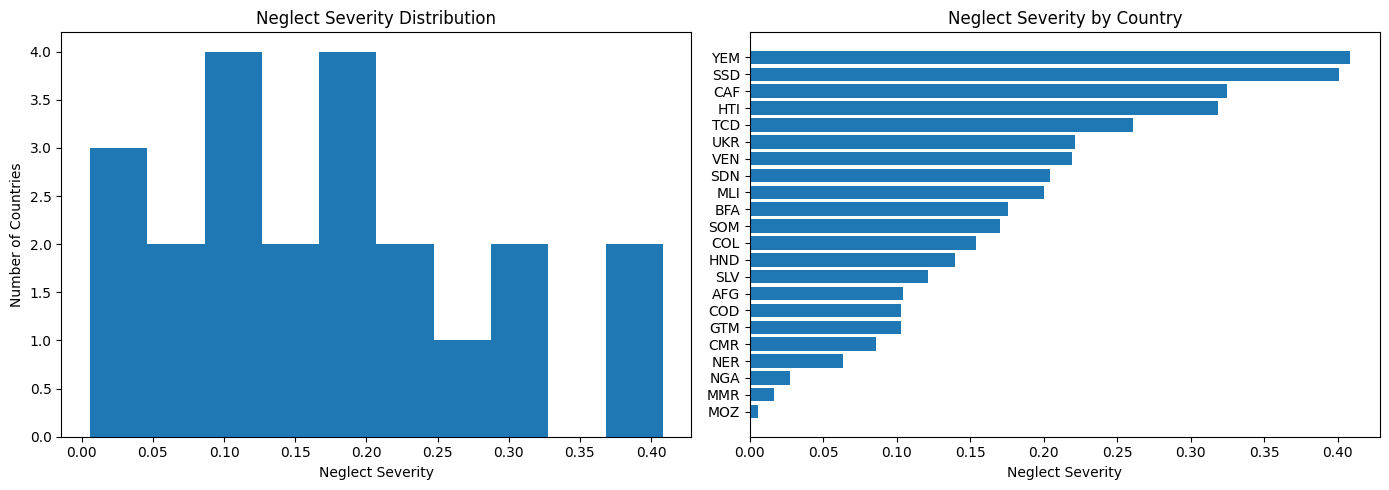

In [128]:
import matplotlib.pyplot as plt

# sort once for the bar chart
df_sorted = df_hpc_2025_cleaned.sort_values("Neglect Severity", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: distribution
axes[0].hist(df_hpc_2025_cleaned["Neglect Severity"], bins=10)
axes[0].set_title("Neglect Severity Distribution")
axes[0].set_xlabel("Neglect Severity")
axes[0].set_ylabel("Number of Countries")

# Right: by country (horizontal bar)
axes[1].barh(df_sorted["Country ISO3"], df_sorted["Neglect Severity"])
axes[1].set_title("Neglect Severity by Country")
axes[1].set_xlabel("Neglect Severity")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


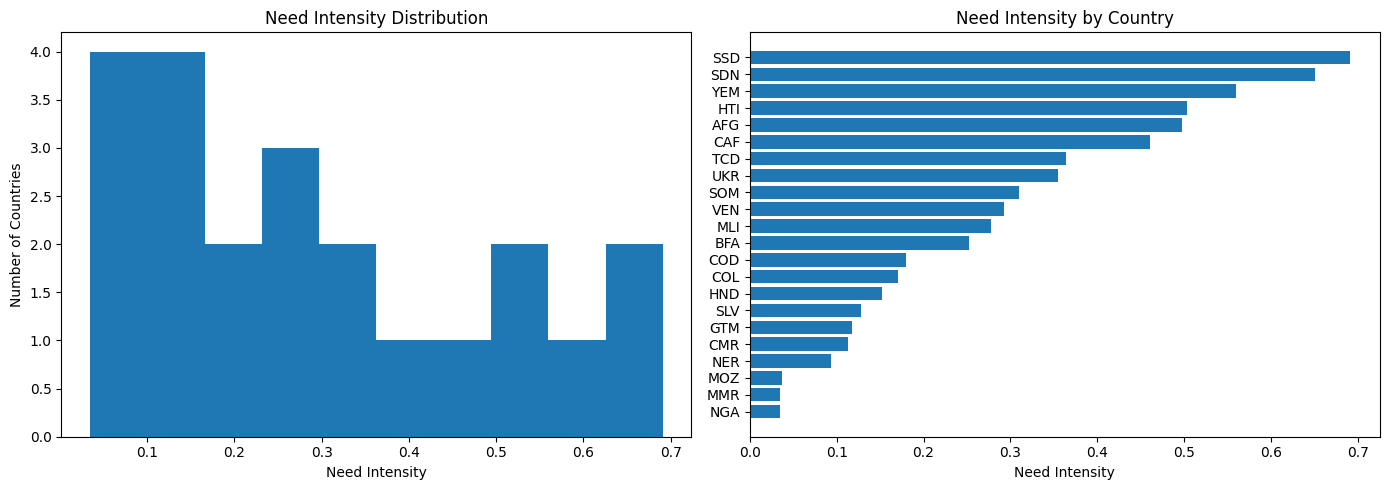

In [129]:
df_sorted = df_hpc_2025_cleaned.sort_values("Need Intensity", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_hpc_2025_cleaned["Need Intensity"], bins=10)
axes[0].set_title("Need Intensity Distribution")
axes[0].set_xlabel("Need Intensity")
axes[0].set_ylabel("Number of Countries")

axes[1].barh(df_sorted["Country ISO3"], df_sorted["Need Intensity"])
axes[1].set_title("Need Intensity by Country")
axes[1].set_xlabel("Need Intensity")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


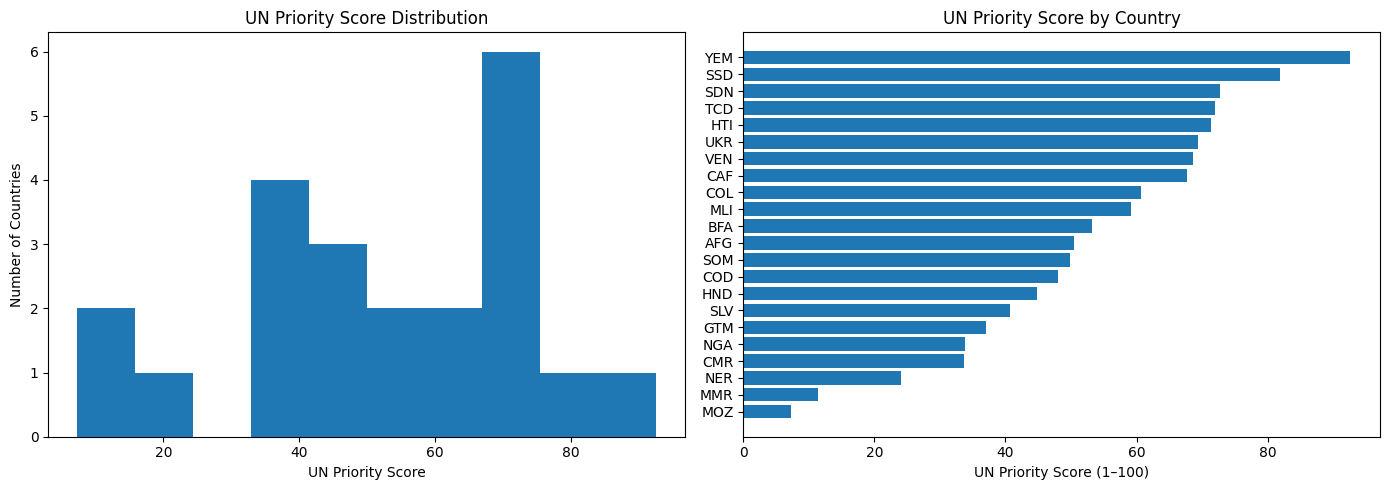

In [130]:
df_sorted = df_hpc_2025_cleaned.sort_values("UN Priority Score", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_hpc_2025_cleaned["UN Priority Score"], bins=10)
axes[0].set_title("UN Priority Score Distribution")
axes[0].set_xlabel("UN Priority Score")
axes[0].set_ylabel("Number of Countries")

axes[1].barh(df_sorted["Country ISO3"], df_sorted["UN Priority Score"])
axes[1].set_title("UN Priority Score by Country")
axes[1].set_xlabel("UN Priority Score (1–100)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

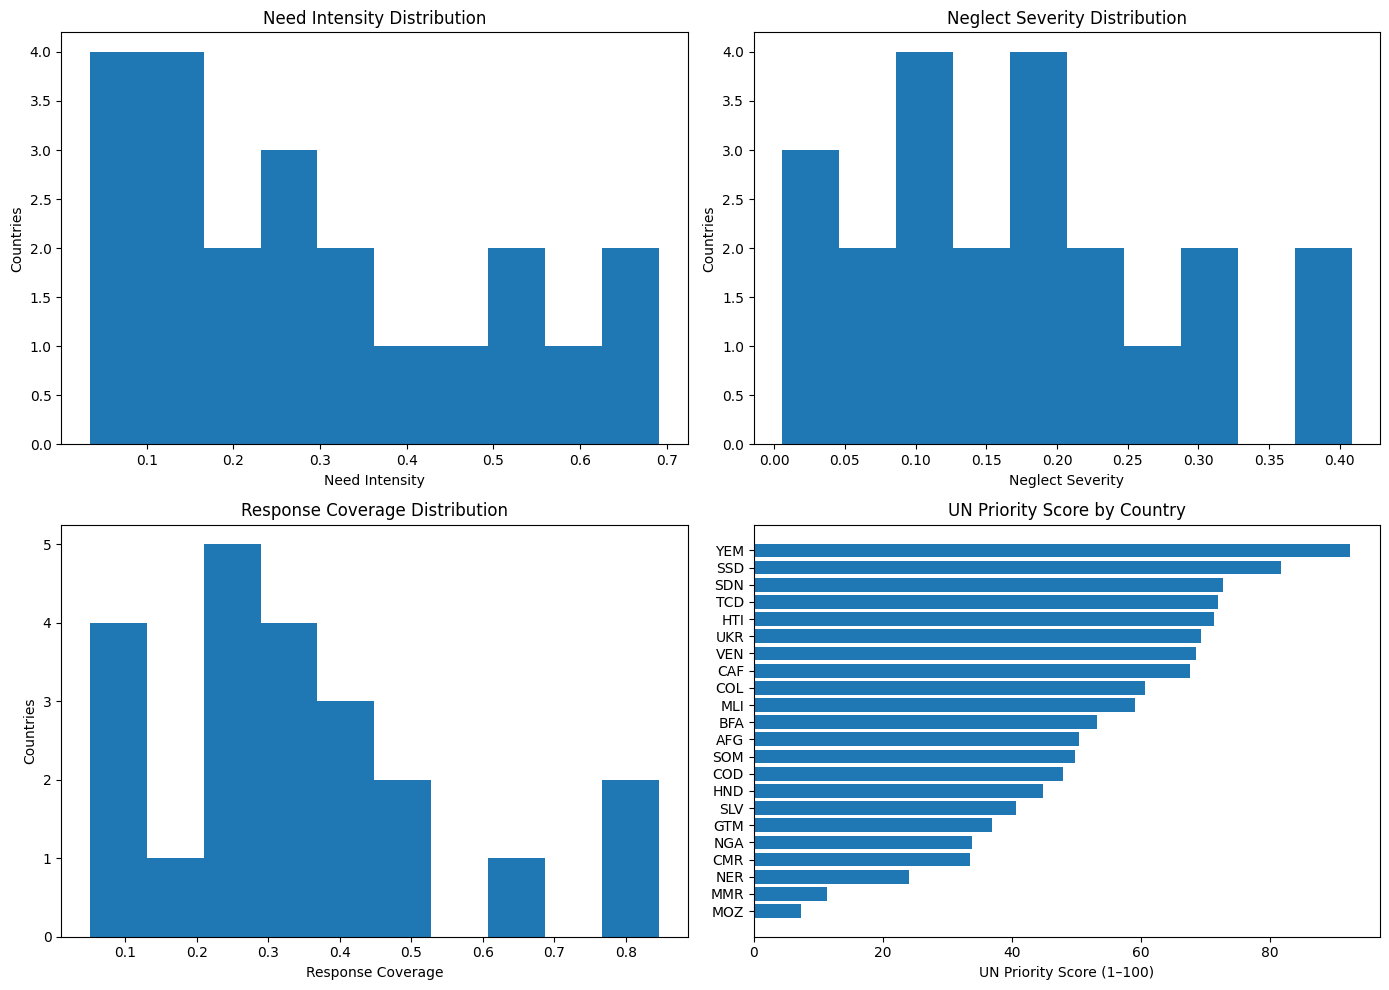

In [131]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (0,0) Need Intensity distribution
axes[0,0].hist(df_hpc_2025_cleaned["Need Intensity"], bins=10)
axes[0,0].set_title("Need Intensity Distribution")
axes[0,0].set_xlabel("Need Intensity")
axes[0,0].set_ylabel("Countries")

# (0,1) Neglect Severity distribution
axes[0,1].hist(df_hpc_2025_cleaned["Neglect Severity"], bins=10)
axes[0,1].set_title("Neglect Severity Distribution")
axes[0,1].set_xlabel("Neglect Severity")
axes[0,1].set_ylabel("Countries")

# (1,0) Response Coverage distribution
axes[1,0].hist(df_hpc_2025_cleaned["Response Coverage"], bins=10)
axes[1,0].set_title("Response Coverage Distribution")
axes[1,0].set_xlabel("Response Coverage")
axes[1,0].set_ylabel("Countries")

# (1,1) UN Priority Score by country
df_sorted = df_hpc_2025_cleaned.sort_values("UN Priority Score", ascending=False)
axes[1,1].barh(df_sorted["Country ISO3"], df_sorted["UN Priority Score"])
axes[1,1].set_title("UN Priority Score by Country")
axes[1,1].set_xlabel("UN Priority Score (1–100)")
axes[1,1].invert_yaxis()

plt.tight_layout()
plt.show()

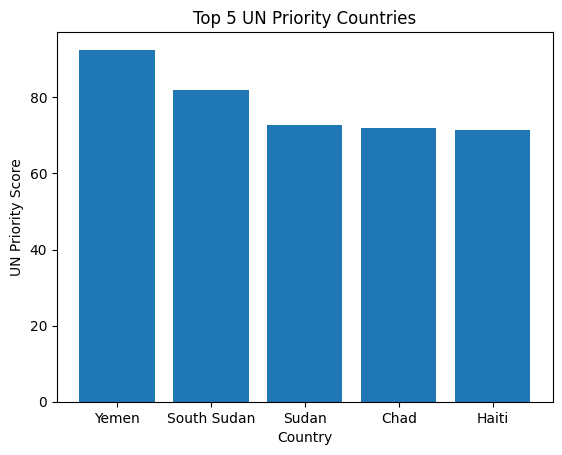

In [132]:
top5 = df_hpc_2025_cleaned.sort_values("UN Priority Score", ascending=False).head(5)

plt.figure()
plt.bar(["Yemen", "South Sudan", "Sudan", "Chad", "Haiti"], top5["UN Priority Score"])
plt.xlabel("Country")
plt.ylabel("UN Priority Score")
plt.title("Top 5 UN Priority Countries")
plt.show()

##Financial + HPC Data

In [153]:
import pandas as pd
import numpy as np

fin = df_finances.copy()
fin["Country ISO3"] = fin["Country ISO3"].astype(str).str.strip()

# 2025 only
fin_2025 = fin[fin["AllocationYear"] == 2025].copy()

# money numeric
fin_2025["Budget"] = pd.to_numeric(fin_2025["Budget"], errors="coerce")

# aggregate to country
finance_country_2025 = (
    fin_2025.groupby("Country ISO3", as_index=False)
            .agg(
                CBPF_Project_Count_2025=("ChfProjectCode", "count"),
                CBPF_Total_Budget_2025=("Budget", "sum")
            )
)

# merge to HNO (keep ALL HNO countries)
df_merged_2025 = df_hpc_2025_cleaned.merge(finance_country_2025, on="Country ISO3", how="left")

# fill missing finance with 0 = no CBPF in 2025
df_merged_2025[["CBPF_Project_Count_2025", "CBPF_Total_Budget_2025"]] = (
    df_merged_2025[["CBPF_Project_Count_2025", "CBPF_Total_Budget_2025"]].fillna(0)
)

# intensity metrics
df_merged_2025["CBPF_Budget_per_InNeed_2025"] = np.where(
    df_merged_2025["In Need"] > 0,
    df_merged_2025["CBPF_Total_Budget_2025"] / df_merged_2025["In Need"],
    0
)

df_merged_2025["CBPF_Projects_per_100k_InNeed_2025"] = np.where(
    df_merged_2025["In Need"] > 0,
    (df_merged_2025["CBPF_Project_Count_2025"] / df_merged_2025["In Need"]) * 100000,
    0
)

# check how many zeros are "real"
print("HNO countries:", df_merged_2025["Country ISO3"].nunique())
print("Countries with any CBPF projects in 2025:", (df_merged_2025["CBPF_Project_Count_2025"] > 0).sum())

df_merged_2025

HNO countries: 22
Countries with any CBPF projects in 2025: 17


,Country ISO3,Description,Cluster,Population,In Need,Targeted,Reached,Need Intensity,Response Coverage,Targeting Efficiency,...,Need Intensity Score,Neglect Severity Score,Unmet Need Score,Low Coverage Score,UN Priority Score,UN Priority Score (35–100),CBPF_Project_Count_2025,CBPF_Total_Budget_2025,CBPF_Budget_per_InNeed_2025,CBPF_Projects_per_100k_InNeed_2025
0,AFG,Final HRP caseload,ALL,46024352.0,22887726.0,16790412.0,18100000.0,0.497296,0.790817,1.077996,...,81.818182,36.363636,59.090909,9.090909,50.5,68.0,118.0,7.314795e+07,3.195946,0.515560
1,BFA,HNRP 2025,ALL,23449865.0,5915136.0,3672506.0,1800000.0,0.252246,0.304304,0.490129,...,50.000000,59.090909,50.000000,50.000000,53.2,70.0,14.0,8.997558e+06,1.521108,0.236681
2,CAF,CAR HNRP 2025,ALL,5296124.0,2440338.0,1772631.0,720000.0,0.460778,0.295041,0.406176,...,77.272727,90.909091,22.727273,54.545455,67.7,81.1,11.0,5.300000e+06,2.171830,0.450757
3,CMR,Final HRP caseload,ALL,29400000.0,3322058.0,2100146.0,800000.0,0.112995,0.240815,0.380926,...,22.727273,22.727273,36.363636,77.272727,33.6,55.1,0.0,0.000000e+00,0.000000,0.000000
4,COD,Final HRP caseload,ALL,117808862.0,21241767.0,10988449.0,9100000.0,0.180307,0.428401,0.828142,...,45.454545,31.818182,95.454545,27.272727,48.0,66.1,50.0,2.299657e+07,1.082611,0.235385
5,COL,Final caseload,ALL,53110609.0,9053352.0,1991880.0,890000.0,0.170462,0.098306,0.446814,...,40.909091,50.000000,86.363636,90.909091,60.7,75.7,0.0,0.000000e+00,0.000000,0.000000
6,GTM,Final HNRP caseload,ALL,18400000.0,2163953.0,1000000.0,275000.0,0.117606,0.127082,0.275000,...,27.272727,27.272727,31.818182,86.363636,37.0,57.7,0.0,0.000000e+00,0.000000,0.000000
7,HND,Final HNRP caseload,ALL,10800000.0,1640224.0,796974.0,132000.0,0.151873,0.080477,0.165626,...,36.363636,45.454545,18.181818,95.454545,44.8,63.6,0.0,0.000000e+00,0.000000,0.000000
8,HTI,Final figures,ALL,11899555.0,5986456.0,3941924.0,2200000.0,0.503082,0.367496,0.558103,...,86.363636,86.363636,45.454545,40.909091,71.4,83.9,1.0,5.000000e+05,0.083522,0.016704
9,MLI,Final HNRP Caseload,ALL,23134540.0,6431534.0,4709012.0,1800000.0,0.278006,0.279871,0.382246,...,54.545455,63.636364,54.545455,63.636364,59.1,74.5,15.0,8.012337e+06,1.245789,0.233226


In [156]:
df_only_funded_2025 = df_merged_2025[df_merged_2025["CBPF_Project_Count_2025"] > 0].copy()
df_only_funded_2025 = df_only_funded_2025.reset_index(drop=True)
df_only_funded_2025

,Country ISO3,Description,Cluster,Population,In Need,Targeted,Reached,Need Intensity,Response Coverage,Targeting Efficiency,...,Need Intensity Score,Neglect Severity Score,Unmet Need Score,Low Coverage Score,UN Priority Score,UN Priority Score (35–100),CBPF_Project_Count_2025,CBPF_Total_Budget_2025,CBPF_Budget_per_InNeed_2025,CBPF_Projects_per_100k_InNeed_2025
0,AFG,Final HRP caseload,ALL,46024352.0,22887726.0,16790412.0,18100000.0,0.497296,0.790817,1.077996,...,81.818182,36.363636,59.090909,9.090909,50.5,68.0,118.0,7.314795e+07,3.195946,0.515560
1,BFA,HNRP 2025,ALL,23449865.0,5915136.0,3672506.0,1800000.0,0.252246,0.304304,0.490129,...,50.000000,59.090909,50.000000,50.000000,53.2,70.0,14.0,8.997558e+06,1.521108,0.236681
2,CAF,CAR HNRP 2025,ALL,5296124.0,2440338.0,1772631.0,720000.0,0.460778,0.295041,0.406176,...,77.272727,90.909091,22.727273,54.545455,67.7,81.1,11.0,5.300000e+06,2.171830,0.450757
3,COD,Final HRP caseload,ALL,117808862.0,21241767.0,10988449.0,9100000.0,0.180307,0.428401,0.828142,...,45.454545,31.818182,95.454545,27.272727,48.0,66.1,50.0,2.299657e+07,1.082611,0.235385
4,HTI,Final figures,ALL,11899555.0,5986456.0,3941924.0,2200000.0,0.503082,0.367496,0.558103,...,86.363636,86.363636,45.454545,40.909091,71.4,83.9,1.0,5.000000e+05,0.083522,0.016704
5,MLI,Final HNRP Caseload,ALL,23134540.0,6431534.0,4709012.0,1800000.0,0.278006,0.279871,0.382246,...,54.545455,63.636364,54.545455,63.636364,59.1,74.5,15.0,8.012337e+06,1.245789,0.233226
6,MMR,Final caseload,ALL,57000000.0,1957173.0,1132893.0,1000000.0,0.034336,0.510941,0.882696,...,9.090909,9.090909,13.636364,18.181818,11.4,38.1,59.0,3.484958e+07,17.806079,3.014552
7,MOZ,Final caseload,ALL,34900000.0,1305029.0,1097096.0,1105000.0,0.037393,0.846724,1.007204,...,13.636364,4.545455,4.545455,4.545455,7.3,35.0,12.0,2.287877e+06,1.753124,0.919520
8,NER,HPC 2025,ALL,27522775.0,2580329.0,2132111.0,844290.0,0.093753,0.327202,0.395988,...,18.181818,18.181818,27.272727,45.454545,24.1,47.8,9.0,4.998012e+06,1.936967,0.348793
9,NGA,Final caseload,ALL,229200000.0,7847048.0,3584107.0,1600000.0,0.034237,0.203898,0.446415,...,4.545455,13.636364,77.272727,81.818182,33.9,55.3,76.0,1.679802e+07,2.140681,0.968517


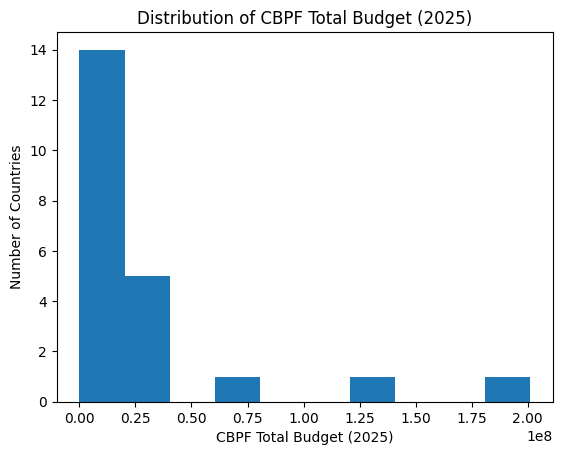

In [158]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df_merged_2025["CBPF_Total_Budget_2025"], bins=10)
plt.xlabel("CBPF Total Budget (2025)")
plt.ylabel("Number of Countries")
plt.title("Distribution of CBPF Total Budget (2025)")
plt.show()


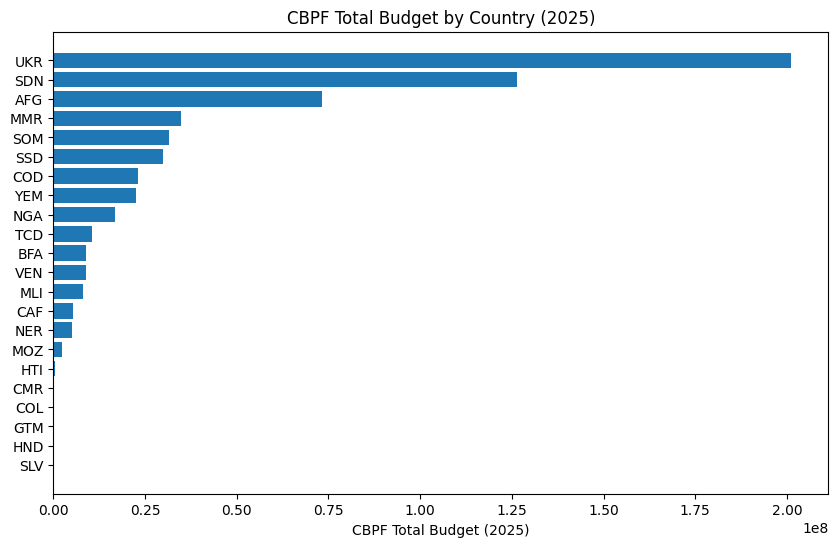

In [159]:
df_sorted = df_merged_2025.sort_values("CBPF_Total_Budget_2025", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(df_sorted["Country ISO3"], df_sorted["CBPF_Total_Budget_2025"])
plt.xlabel("CBPF Total Budget (2025)")
plt.title("CBPF Total Budget by Country (2025)")
plt.gca().invert_yaxis()
plt.show()


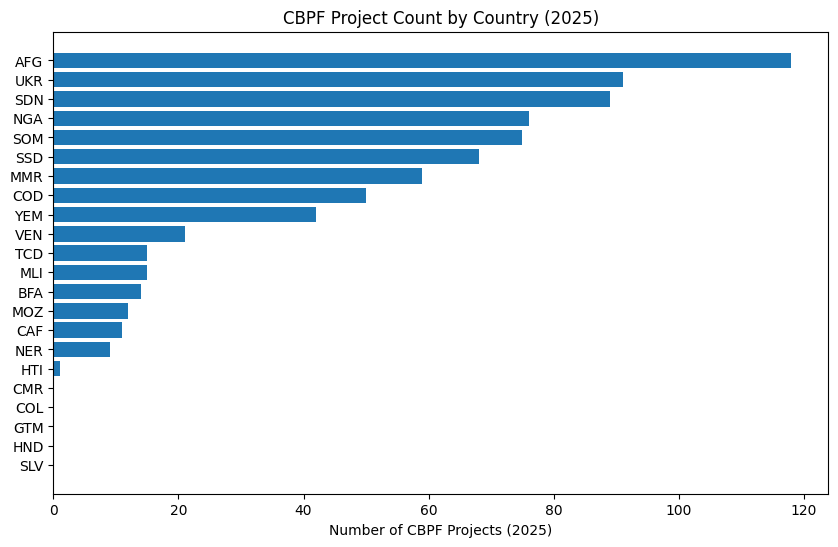

In [161]:
df_sorted = df_merged_2025.sort_values("CBPF_Project_Count_2025", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(df_sorted["Country ISO3"], df_sorted["CBPF_Project_Count_2025"])
plt.xlabel("Number of CBPF Projects (2025)")
plt.title("CBPF Project Count by Country (2025)")
plt.gca().invert_yaxis()
plt.show()


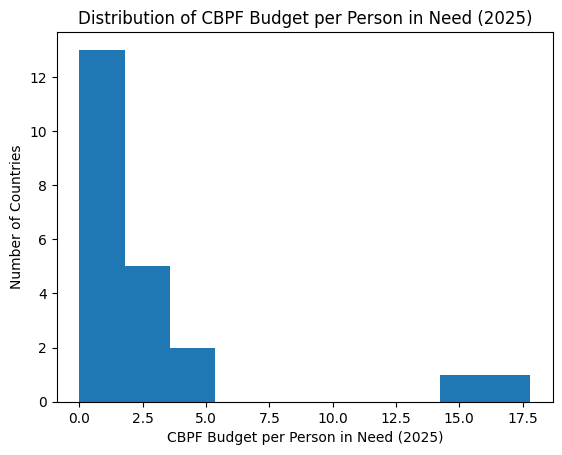

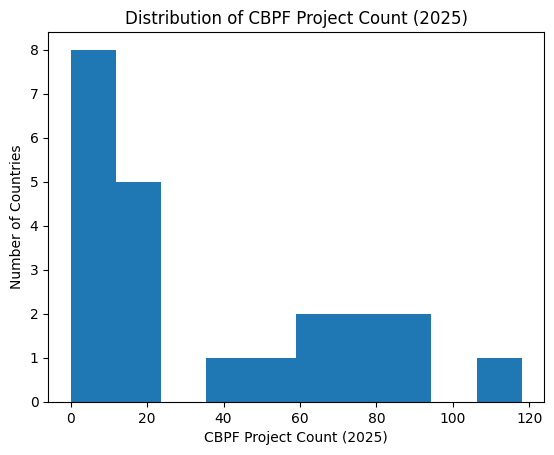

In [160]:
plt.figure()
plt.hist(df_merged_2025["CBPF_Project_Count_2025"], bins=10)
plt.xlabel("CBPF Project Count (2025)")
plt.ylabel("Number of Countries")
plt.title("Distribution of CBPF Project Count (2025)")
plt.show()


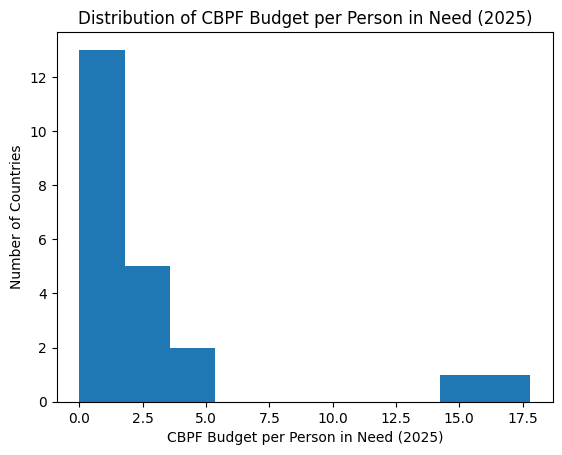

In [163]:
plt.figure()
plt.hist(df_merged_2025["CBPF_Budget_per_InNeed_2025"], bins=10)
plt.xlabel("CBPF Budget per Person in Need (2025)")
plt.ylabel("Number of Countries")
plt.title("Distribution of CBPF Budget per Person in Need (2025)")
plt.show()


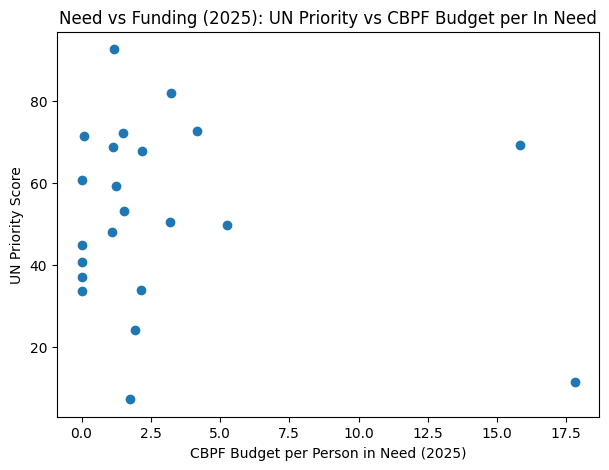

In [164]:
plt.figure(figsize=(7, 5))
plt.scatter(
    df_merged_2025["CBPF_Budget_per_InNeed_2025"],
    df_merged_2025["UN Priority Score"]
)
plt.xlabel("CBPF Budget per Person in Need (2025)")
plt.ylabel("UN Priority Score")
plt.title("Need vs Funding (2025): UN Priority vs CBPF Budget per In Need")
plt.show()


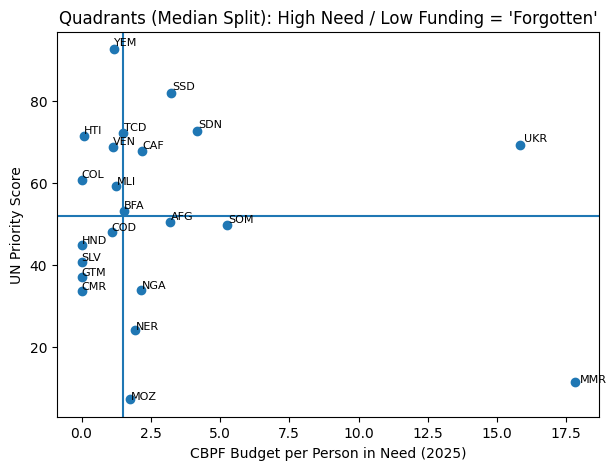

In [173]:
x_med = df["CBPF_Budget_per_InNeed_2025"].median()
y_med = df["UN Priority Score"].median()

plt.figure(figsize=(7, 5))
plt.scatter(
    df["CBPF_Budget_per_InNeed_2025"],
    df["UN Priority Score"]
)

# median lines
plt.axvline(x=x_med)
plt.axhline(y=y_med)

plt.xlabel("CBPF Budget per Person in Need (2025)")
plt.ylabel("UN Priority Score")
plt.title("Quadrants (Median Split): High Need / Low Funding = 'Forgotten'")
for _, row in df.iterrows():
    plt.text(
        row["CBPF_Budget_per_InNeed_2025"] * 1.01,
        row["UN Priority Score"] * 1.01,
        row["Country ISO3"],
        fontsize=8
    )

plt.show()



##Future Forcasting

In [182]:
df = df_merged_2025.copy()

# Make sure the key columns are numeric
df["UN Priority Score"] = pd.to_numeric(df["UN Priority Score"], errors="coerce")
df["CBPF_Budget_per_InNeed_2025"] = pd.to_numeric(df["CBPF_Budget_per_InNeed_2025"], errors="coerce")

# If funding is missing, treat it as 0 (no CBPF in 2025)
df["CBPF_Budget_per_InNeed_2025"] = df["CBPF_Budget_per_InNeed_2025"].fillna(0)

# Percentile-normalize need and funding (0..1)
df["Need_norm"] = df["UN Priority Score"].rank(pct=True)
df["Funding_norm"] = df["CBPF_Budget_per_InNeed_2025"].rank(pct=True)

# Mismatch: positive means "high need, low funding"
df["Mismatch_Score"] = df["Need_norm"] - df["Funding_norm"]

df.head()


,Country ISO3,Description,Cluster,Population,In Need,Targeted,Reached,Need Intensity,Response Coverage,Targeting Efficiency,...,Low Coverage Score,UN Priority Score,UN Priority Score (35–100),CBPF_Project_Count_2025,CBPF_Total_Budget_2025,CBPF_Budget_per_InNeed_2025,CBPF_Projects_per_100k_InNeed_2025,Need_norm,Funding_norm,Mismatch_Score
0,AFG,Final HRP caseload,ALL,46024352.0,22887726.0,16790412.0,18100000.0,0.497296,0.790817,1.077996,...,9.090909,50.5,68.0,118.0,73147945.37,3.195946,0.515560,0.500000,0.772727,-0.272727
1,BFA,HNRP 2025,ALL,23449865.0,5915136.0,3672506.0,1800000.0,0.252246,0.304304,0.490129,...,50.000000,53.2,70.0,14.0,8997558.19,1.521108,0.236681,0.545455,0.545455,0.000000
2,CAF,CAR HNRP 2025,ALL,5296124.0,2440338.0,1772631.0,720000.0,0.460778,0.295041,0.406176,...,54.545455,67.7,81.1,11.0,5300000.01,2.171830,0.450757,0.681818,0.727273,-0.045455
3,CMR,Final HRP caseload,ALL,29400000.0,3322058.0,2100146.0,800000.0,0.112995,0.240815,0.380926,...,77.272727,33.6,55.1,0.0,0.00,0.000000,0.000000,0.181818,0.136364,0.045455
4,COD,Final HRP caseload,ALL,117808862.0,21241767.0,10988449.0,9100000.0,0.180307,0.428401,0.828142,...,27.272727,48.0,66.1,50.0,22996566.57,1.082611,0.235385,0.409091,0.318182,0.090909


In [176]:
mismatch_ranked = df.sort_values("Mismatch_Score", ascending=False)[
    ["Country ISO3", "UN Priority Score", "CBPF_Budget_per_InNeed_2025", "Mismatch_Score"]
].reset_index(drop=True)

mismatch_ranked.head(10)


,Country ISO3,UN Priority Score,CBPF_Budget_per_InNeed_2025,Mismatch_Score
0,YEM,92.5,1.157719,0.590909
1,HTI,71.4,0.083522,0.545455
2,COL,60.7,0.000000,0.500000
3,TCD,72.0,1.506022,0.363636
4,VEN,68.6,1.128629,0.363636
5,HND,44.8,0.000000,0.227273
6,SLV,40.7,0.000000,0.181818
7,MLI,59.1,1.245789,0.136364
8,SSD,81.8,3.230582,0.136364
9,GTM,37.0,0.000000,0.136364


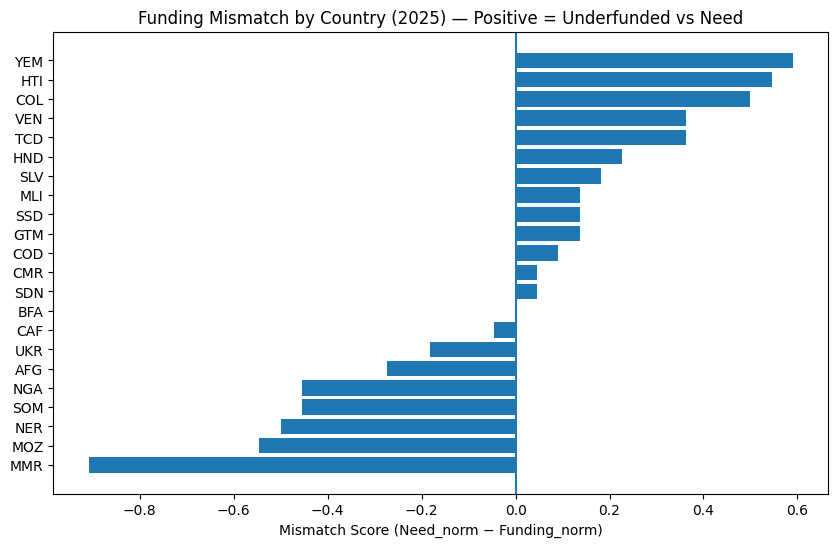

In [177]:
plot_df = df.sort_values("Mismatch_Score", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Country ISO3"], plot_df["Mismatch_Score"])
plt.axvline(0)
plt.xlabel("Mismatch Score (Need_norm − Funding_norm)")
plt.title("Funding Mismatch by Country (2025) — Positive = Underfunded vs Need")
plt.show()


In [179]:
TOTAL_NEW_MONEY = 100_000_000

# Only allocate to countries with positive mismatch
weights = df["Mismatch_Score"].clip(lower=0)

df["Suggested_Allocation_$"] = np.where(
    weights.sum() > 0,
    weights / weights.sum() * TOTAL_NEW_MONEY,
    0
)

allocation_table = df.sort_values("Suggested_Allocation_$", ascending=False)[
    ["Country ISO3", "Mismatch_Score", "UN Priority Score", "CBPF_Budget_per_InNeed_2025", "Suggested_Allocation_$"]
].reset_index(drop=True)
allocation_table["Suggested_Allocation_$M"] = (allocation_table["Suggested_Allocation_$"] / 1_000_000).round(2)
allocation_table.drop(columns=["Suggested_Allocation_$"]).head(10)


allocation_table.head(10)


,Country ISO3,Mismatch_Score,UN Priority Score,CBPF_Budget_per_InNeed_2025,Suggested_Allocation_$,Suggested_Allocation_$M
0,YEM,0.590909,92.5,1.157719,1.756757e+07,17.57
1,HTI,0.545455,71.4,0.083522,1.621622e+07,16.22
2,COL,0.500000,60.7,0.000000,1.486486e+07,14.86
3,TCD,0.363636,72.0,1.506022,1.081081e+07,10.81
4,VEN,0.363636,68.6,1.128629,1.081081e+07,10.81
5,HND,0.227273,44.8,0.000000,6.756757e+06,6.76
6,SLV,0.181818,40.7,0.000000,5.405405e+06,5.41
7,MLI,0.136364,59.1,1.245789,4.054054e+06,4.05
8,SSD,0.136364,81.8,3.230582,4.054054e+06,4.05
9,GTM,0.136364,37.0,0.000000,4.054054e+06,4.05


In [180]:
top_underfunded = mismatch_ranked.head(5)["Country ISO3"].tolist()
top_alloc = allocation_table.head(5)[["Country ISO3", "Suggested_Allocation_$"]].copy()
top_alloc["Suggested_Allocation_$M"] = (top_alloc["Suggested_Allocation_$"] / 1_000_000).round(2)

print("Top 5 'forgotten' crises (highest mismatch):", top_underfunded)
print("\nIf we allocated $100M purely by mismatch, top recipients would be:")
print(top_alloc[["Country ISO3", "Suggested_Allocation_$M"]])


Top 5 'forgotten' crises (highest mismatch): ['YEM', 'HTI', 'COL', 'TCD', 'VEN']

If we allocated $100M purely by mismatch, top recipients would be:
  Country ISO3  Suggested_Allocation_$M
0          YEM                    17.57
1          HTI                    16.22
2          COL                    14.86
3          TCD                    10.81
4          VEN                    10.81


We rank countries by humanitarian need (UN Priority Score) and by CBPF funding intensity (budget per person in need). We percentile-normalize each axis and define a Mismatch Score = Need_norm − Funding_norm. Countries with high positive mismatch are likely underfunded relative to their crisis severity. We use the mismatch score as weights to simulate a transparent reallocation of hypothetical new funding.